# Fig. 5c-e: Neural value within and across targets

[AI generated summary] In each session, trials are grouped by the chosen target. For each target, a decoder of the previous outcome (logistic regression, as in Fig. 4) is fit on the population activity, and the neural value is the projection on its decision vector: for the trials of the same target (within target, leave-one-out cross-validation) and for the trials of the other two targets (across target). The trial-to-trial change of this neural value is compared after rewarded and unrewarded trials, when the target matches (within target) or not (across target):
- **Fig. 5c**: within- and across-target changes in an example MCC session (KA, 210322).
- **Fig. 5d**: session averages of the within- vs. across-target changes (sessions with a delta-rule consistent within-target update), with Wilcoxon tests.
- **Fig. 5e**: fraction of sessions supporting the standard RL, inferential RL and foraging hypotheses.

The statistics reported in the paper are printed below the figures. **How to run:** run all cells. Figures are saved in `figs/fig5/`.

**Results:** precomputed results are provided in `results/population_decoding/across_target_before_fb` (see the README). To recompute them, run in this folder: `python run_neural_value_across_target.py before_fb` (several hours on a server).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
##% title Imports
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
import os
import pandas as pd
import matplotlib.colors as mcolors

from helpers_analysis import create_r_style_plot, fit_mixed_glm, stat_tests_mixed_glm, add_hypothesis
from helpers_analysis import print_stat_header, wilcoxon_signed_rank, bootstrap_median_ci
from helpers import get_data, merge_alter_values, make_session_summary, get_session_mean_value, extract_hypothesis, prepare_2d_scatter_data
import popy.config as cfg
from popy.config import PROJECT_PATH_LOCAL as PATH
from popy.config import COLORS as COLORS
from popy.config import RESULTS_PATH

PATH = cfg.PROJECT_PATH_LOCAL

plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def plot_RL_vs_forage_single_sess_horizontal(ax=None, data=None, x_col=None, y_col=None, title=None, session_col='session', paper_format=False):
    """Create R-style plot with box and jittered points (horizontal version)."""
    palette = COLORS
    axis = ax
    if paper_format:
        fontsize = 8
        h = 2
        w = 2
        s = 15
    else:
        fontsize = 18
        h = 3
        w = 4
        s = 10

    if axis is None:
        fig, ax = plt.subplots(1, 1, figsize=(w, h))

    data = data.copy().sort_values(by=x_col)
    categories = data[x_col].unique()
    y_positions = [0, 0.5]

    lw = 0.4

    # Create slimmer horizontal boxplots.
    box_data = [data.loc[data[x_col] == cat, y_col].values for cat in categories]
    bp = ax.boxplot(
        box_data,
        positions=y_positions,
        widths=0.35,
        patch_artist=True,
        boxprops=dict(alpha=0.7),
        showfliers=False,
        medianprops=dict(color='black'),
        flierprops=dict(markersize=3, alpha=0.5),
        vert=False,
    )

    colors = [palette[cat] for cat in categories]
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)

    jitter_positions = {}

    # Add jittered points (horizontal scatter) with reduced jitter and higher transparency.
    for i, cat in enumerate(categories):
        x_data = data.loc[data[x_col] == cat, y_col].values
        base_rgba = mcolors.to_rgba(palette[cat], alpha=0.35)
        edge_color = (base_rgba[0] * 0.7, base_rgba[1] * 0.7, base_rgba[2] * 0.7, 1.0)
        y_jitter = np.random.normal(-1, 0.08, size=len(x_data))

        zorder_values = np.random.uniform(10, 1000, size=len(x_data))
        for x_val, y_val, z_val in zip(x_data, y_jitter, zorder_values):
            ax.scatter(
                x_val,
                y_val,
                s=s,
                facecolors=base_rgba,
                edgecolors=edge_color,
                linewidth=0.5,
                zorder=z_val,
            )

        if session_col is not None:
            session_data = data.loc[data[x_col] == cat, session_col].values
            jitter_positions[cat] = dict(zip(session_data, zip(x_data, y_jitter)))

    if len(categories) == 2:
        group1_data = data.loc[data[x_col] == categories[0], y_col]
        group2_data = data.loc[data[x_col] == categories[1], y_col]
        _, p_value = stats.mannwhitneyu(group1_data, group2_data, alternative='two-sided')

        mean1 = group1_data.mean()
        mean2 = group2_data.mean()
        line_height = max(y_positions) + 0.8

        if p_value < 0.001:
            significance = '***'
        elif p_value < 0.01:
            significance = '**'
        elif p_value < 0.05:
            significance = '*'
        else:
            significance = 'n.s.'

        ax.plot([mean1, mean2], [line_height, line_height], '-k', lw=2 * lw)
        ax.plot([mean1, mean1], [line_height - 0.1, line_height], '-k', lw=2 * lw)
        ax.plot([mean2, mean2], [line_height - 0.1, line_height], '-k', lw=2 * lw)
        ax.text(
            (mean1 + mean2) / 2,
            line_height + 0.05,
            f'{significance} (n={len(group1_data)})',
            va='bottom',
            ha='center',
            fontsize=fontsize,
        )

    ax.axhline(-1, linestyle='-', alpha=1, color='black', lw=4 * lw, zorder=1)

    vline_bottom = min(y_positions) - 1
    vline_top = max(y_positions) + 0.5
    ax.vlines(0, vline_bottom, vline_top, linestyle='-', color='black', lw=1, zorder=0)

    ax.set_yticks([])
    ax.set_xlabel('Change in neural value \n$\\Delta V = V_t - V_{t-1}$', fontsize=fontsize)
    ax.tick_params(axis='x', length=0)

    ax.set_ylabel('')
    ax.set_title(title, fontsize=fontsize)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.grid(axis='x', linestyle='--', alpha=0.5, zorder=0)

    if axis is None:
        return fig, ax
    return ax


def plot_2d_scatter_with_marginals(scatter_df, x_data, y_data,
                                   session_col='session', feedback_col='feedback',
                                   value_col='dV_neural', title=None, palette=None,
                                   paper_format=False, fig_label='Fig. 5d', n_comparisons=3):
    """Plot 2D scatter with marginal distributions from preprocessed data.

    fig_label: figure panel name used in the printed statistics
    n_comparisons: number of tests for the Bonferroni correction (default: 3 regions)
    """
    if palette is None:
        palette = {'0': 'tab:red', '1': 'tab:green'}

    def paired_feedback_test(data, label):
        # paired test: each session contributes one value per feedback (same as Fig. 4e)
        pair_keys = [col for col in ['monkey', session_col] if col in data.columns]
        paired = data.pivot_table(index=pair_keys, columns=feedback_col, values=value_col).dropna()
        diffs = paired[1] - paired[0]
        stat, p_value, r_rb, n_used = wilcoxon_signed_rank(diffs.values)

        print_stat_header(label, data)
        print(f"  Group test: two-sided Wilcoxon signed-rank test, paired by session, {value_col} of 1 - 0 ({feedback_col})")
        print(f"  n = {len(diffs)} sessions ({n_used} non-zero differences); median difference = {np.median(diffs):.3f} "
              f"(IQR {np.percentile(diffs, 25):.3f} to {np.percentile(diffs, 75):.3f})")
        ci_low, ci_high = bootstrap_median_ci(diffs.values)
        print(f"  95% CI of the median difference (bootstrap over sessions, 10000 resamples): [{ci_low:.3f}, {ci_high:.3f}]")
        print(f"  W = {stat:.1f}, p = {p_value:.3e}, p (Bonferroni x{n_comparisons}) = {min(p_value * n_comparisons, 1):.3e}")
        print(f"  Effect size: matched-pairs rank-biserial r = {r_rb:.3f}")
        return p_value

    if paper_format:
        plt.rcParams.update({'font.size': 8})
        s = 15
        h = 2.5 * 5.3 / 6
        w = 2.5 * 5.3 / 6
        lw = 0.4
    else:
        plt.rcParams.update({'font.size': 12})
        s = 30
        lw = 0.8
        h, w = 6, 6

    fig = plt.figure(figsize=(w, h))
    gs = fig.add_gridspec(
        3,
        3,
        width_ratios=[1, 4, 1],
        height_ratios=[1, 4, 1],
        hspace=0.05,
        wspace=0.05,
    )

    ax_main = fig.add_subplot(gs[1, 1])
    ax_top = fig.add_subplot(gs[0, 1], sharex=ax_main)
    ax_right = fig.add_subplot(gs[1, 2], sharey=ax_main)

    feedback_levels = ['0', '1']

    if not scatter_df.empty:
        for feedback in feedback_levels:
            for signif_same in [True, False]:
                for signif_alter in [True, False]:
                    mask = (
                        scatter_df['feedback'].eq(feedback)
                        & scatter_df['signif_same'].eq(signif_same)
                        & scatter_df['signif_alter'].eq(signif_alter)
                    )

                    if mask.sum() == 0:
                        continue

                    if not signif_same:
                        ax_main.scatter(
                            scatter_df.loc[mask, 'x'],
                            scatter_df.loc[mask, 'y'],
                            c='black',
                            alpha=0.3,
                            linewidths=lw * 2,
                            s=s / 2,
                            marker='x',
                            zorder=0,
                        )
                    else:
                        ax_main.scatter(
                            scatter_df.loc[mask, 'x'],
                            scatter_df.loc[mask, 'y'],
                            c=palette[feedback] if signif_alter else 'white',
                            alpha=0.7,
                            s=s,
                            edgecolor='black' if signif_alter else palette[feedback],
                            linewidth=lw,
                            label='Unrewarded' if feedback == '0' else 'Rewarded',
                            zorder=10,
                        )

        if session_col == 'session':
            for session in scatter_df['session'].unique():
                session_data = scatter_df[scatter_df['session'] == session]
                if len(session_data) == 2:
                    x_vals = session_data['x'].values
                    y_vals = session_data['y'].values
                    ax_main.plot(x_vals, y_vals, '-', color='gray', alpha=0.3, linewidth=lw, zorder=0)

    lims = [
        np.min([ax_main.get_xlim(), ax_main.get_ylim()]),
        np.max([ax_main.get_xlim(), ax_main.get_ylim()]),
    ]
    #ax_main.plot(lims, lims, 'k--', alpha=0.5, zorder=0, linewidth=lw)
    ax_main.axhline(0, linestyle='--', alpha=0.5, color='black', linewidth=lw, zorder=0)
    ax_main.axvline(0, linestyle='--', alpha=0.5, color='black', linewidth=lw, zorder=0)

    ax_main.set_xlabel('Within-target change\nin neural value')
    ax_main.set_ylabel('Across-target change\nin neural value')

    for fb_id, feedback in enumerate(feedback_levels):
        x_feedback_data = x_data[x_data[feedback_col] == int(feedback)][value_col].values
        if len(x_feedback_data) > 0:
            density = stats.gaussian_kde(x_feedback_data)
            x_range = np.linspace(
                x_feedback_data.min() - 0.1 * np.ptp(x_feedback_data),
                x_feedback_data.max() + 0.1 * np.ptp(x_feedback_data),
                200,
            )
            density_values = density(x_range)
            density_values = density_values / density_values.max() * 0.8

            ax_top.fill_between(
                x_range,
                0,
                density_values,
                color=palette[feedback],
                alpha=0.3,
                edgecolor='black',
                linewidth=lw,
            )

            ax_top.boxplot(
                [x_feedback_data],
                positions=[0.4 - fb_id * 0.2],
                widths=0.2,
                patch_artist=True,
                vert=False,
                boxprops=dict(alpha=0.7, facecolor=palette[feedback]),
                showfliers=False,
                medianprops=dict(color='black'),
            )

    x_data_pos = x_data[x_data['feedback'] == 1][value_col].values
    x_data_neg = x_data[x_data['feedback'] == 0][value_col].values
    if len(x_data_pos) > 0 and len(x_data_neg) > 0:
        p_value_x = paired_feedback_test(x_data, f'{fig_label} (top marginal, within-target)')
        x_pos_center = np.median(x_data_pos)
        x_neg_center = np.median(x_data_neg)
        y_line = 0.9

        ax_top.plot([x_neg_center, x_pos_center], [y_line, y_line], 'k-', linewidth=lw)

        if p_value_x > 0.05:
            p_text_x = 'n.s.'
        elif p_value_x <= 0.001:
            p_text_x = '***'
        elif p_value_x <= 0.01:
            p_text_x = '**'
        else:
            p_text_x = '*'

        ax_top.text(
            (x_neg_center + x_pos_center) / 2,
            y_line * 1.1,
            p_text_x,
            ha='center',
            va='bottom',
            fontsize=plt.rcParams['font.size'] - 1,
        )

    for fb_id, feedback in enumerate(feedback_levels):
        y_feedback_data = y_data[y_data[feedback_col] == int(feedback)][value_col].values
        if len(y_feedback_data) > 0:
            density = stats.gaussian_kde(y_feedback_data)
            y_range = np.linspace(
                y_feedback_data.min() - 0.1 * np.ptp(y_feedback_data),
                y_feedback_data.max() + 0.1 * np.ptp(y_feedback_data),
                200,
            )
            density_values = density(y_range)
            density_values = density_values / density_values.max() * 0.8

            ax_right.fill_betweenx(
                y_range,
                0,
                density_values,
                color=palette[feedback],
                alpha=0.3,
                edgecolor='black',
                linewidth=lw,
            )

            ax_right.boxplot(
                [y_feedback_data],
                positions=[0.4 - fb_id * 0.2],
                widths=0.2,
                patch_artist=True,
                vert=True,
                boxprops=dict(alpha=0.7, facecolor=palette[feedback]),
                showfliers=False,
                medianprops=dict(color='black'),
            )

    y_data_pos = y_data[y_data['feedback'] == 1][value_col].values
    y_data_neg = y_data[y_data['feedback'] == 0][value_col].values
    if len(y_data_pos) > 0 and len(y_data_neg) > 0:
        p_value_y = paired_feedback_test(y_data, f'{fig_label} (right marginal, across-target)')
        y_pos_center = np.median(y_data_pos)
        y_neg_center = np.median(y_data_neg)
        x_line = 0.9

        ax_right.plot([x_line, x_line], [y_neg_center, y_pos_center], 'k-', linewidth=lw)

        if p_value_y > 0.05:
            p_text_y = 'n.s.'
        elif p_value_y <= 0.001:
            p_text_y = '***'
        elif p_value_y <= 0.01:
            p_text_y = '**'
        else:
            p_text_y = '*'

        ax_right.text(
            x_line * 1.3,
            (y_neg_center + y_pos_center) / 2,
            p_text_y,
            ha='center',
            va='center',
            rotation=90,
            fontsize=plt.rcParams['font.size'] - 1,
        )

    ax_top.axvline(0, linestyle='--', alpha=0.5, color='black', linewidth=lw, zorder=0)
    ax_right.axhline(0, linestyle='--', alpha=0.5, color='black', linewidth=lw, zorder=0)

    ax_top.set_xlim(ax_main.get_xlim())
    ax_top.set_ylim(0, 1)
    ax_top.set_yticks([])
    ax_top.spines['top'].set_visible(False)
    ax_top.spines['right'].set_visible(False)
    ax_top.spines['left'].set_visible(False)
    ax_top.tick_params(labelbottom=False)

    ax_right.set_ylim(ax_main.get_ylim())
    ax_right.set_xlim(0, 1)
    ax_right.set_xticks([])
    ax_right.spines['top'].set_visible(False)
    ax_right.spines['right'].set_visible(False)
    ax_right.spines['bottom'].set_visible(False)
    ax_right.tick_params(labelleft=False)

    ax_main.spines['top'].set_visible(False)
    ax_main.spines['right'].set_visible(False)

    n_total = len(np.unique(x_data['session'])) if len(x_data) > 0 else 0
    if title is None:
        plt.suptitle(f'n= {n_total}')
    else:
        plt.suptitle(title)

    return fig, ax_main, ax_top, ax_right


def print_stats_both(stats_summary, printres=True, ax=None, title=None): 
    # Create horizontal bar plot showing proportions for each subregion
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(1.2, 1.5))
    else:
        fig = ax.figure
    plt.rcParams.update({'font.size': 8})
    
    subregions = ['MCC', 'dLPFC', 'vLPFC'][::-1]
    ordered_hypotheses = ['Standard RL', 'Inferential RL', 'Foraging', 'none']
    all_hypotheses = stats_summary['hypothesis'].unique()
    ordered_hypotheses = ordered_hypotheses + [h for h in all_hypotheses if h not in ordered_hypotheses]
    ordered_hypotheses = ordered_hypotheses[::-1]  # Reverse order for plotting
    

    #hypotheses_all = stats_summary['hypothesis'].unique()
    #ordered_hypotheses = [h for h in ordered_hypotheses if h in hypotheses_all]  # Keep only hypotheses that are present in the data
    
    # Calculate proportions and plot bars with slight overlap
    bar_height = 0.23  # Height of each individual bar
    overlap_offset = 0.15  # How much each bar is offset (smaller = more overlap)
    subregion_spacing = 1.0  # Space between subregion groups
    subregion_totals = {}
    
    for s, subregion in enumerate(subregions):
        subregion_data = stats_summary[stats_summary['subregion'] == subregion]
        hypothesis_counts = {hypothesis: subregion_data[subregion_data['hypothesis'] == hypothesis]['count'].sum()
                             for hypothesis in ordered_hypotheses}
        total_sessions = subregion_data['count'].sum()
        subregion_totals[subregion] = int(total_sessions)
        
        # Calculate the center position for this subregion group
        base_y = s * subregion_spacing
        
        for h, hypothesis in enumerate(ordered_hypotheses):
            if hypothesis in hypothesis_counts:
                proportion = hypothesis_counts[hypothesis] / total_sessions
            else:
                proportion = 0
                
            if printres:
                print(f'Subregion: {subregion}, Hypothesis: {hypothesis}, Proportion: {proportion * 100:.1f}% ({hypothesis_counts.get(hypothesis, 0)}/{total_sessions} sessions)')
            
            # Calculate y position with overlap
            # Start from bottom and work up, with each bar slightly offset
            y_pos = base_y - (len(ordered_hypotheses) - 1) * overlap_offset / 2 + h * overlap_offset
            
            color = COLORS.get(hypothesis, 'gray')
            if hypothesis == 'Feedback coding':
                color = 'black'

            bar = ax.barh(y_pos, 
                    proportion * 100, 
                    height=bar_height, 
                    color=color, 
                    label=hypothesis if s == 0 else "",  # Only label once for legend
                    zorder=len(ordered_hypotheses) + h,  # Higher zorder for later hypotheses
                    alpha=0.8, 
                    edgecolor='grey', 
                    linewidth=0.5)
                
            # Add dot at the end of the bar
            ax.scatter(proportion * 100, y_pos, 
                        color=color, s=20, zorder=len(ordered_hypotheses) + h + 100,
                        edgecolor='black', linewidth=0.5)

    # Customize the plot
    ax.set_yticks([s * subregion_spacing for s in range(len(subregions))])
    ytick_labels = [f'{subregion}\nn={subregion_totals.get(subregion, 0)}' for subregion in subregions]
    ax.set_yticklabels(ytick_labels, rotation=0, va='center', ha='center')
    ax.set_xlabel('Percent sessions\n(%)')
    ax.set_xlim(-5, 105)
    # xticks at 0, 50, 100
    ax.set_xticks([0, 50, 100])


    ax.grid(axis='x', linestyle='--', alpha=0.5, zorder=-1)
    
    # Remove spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    #sns.despine(ax=ax, trim=True)
    
    # Create legend - only include hypotheses that actually appear in the data
    present_hypotheses = [h for h in ordered_hypotheses if h in stats_summary['hypothesis'].values]
    legend_handles = [plt.Rectangle((0,0),1,1, 
                                  facecolor=COLORS.get(hypothesis, 'gray'), 
                                  alpha=0.8, 
                                  edgecolor='grey', 
                                  linewidth=0.5) 
                     for hypothesis in present_hypotheses]
    
    if ax is None:
        fig.legend(legend_handles[::-1], present_hypotheses[::-1], loc='center left', bbox_to_anchor=(1, 0.5))
    
    if title is not None:
        ax.set_title(title, fontsize=10)

    return fig, ax, legend_handles, present_hypotheses

---
# Get data

In [4]:
base_path = os.path.join(FIGS_PATH, 'fig5')  # figures are saved here
os.makedirs(base_path, exist_ok=True)

In [5]:
res = get_data(floc=os.path.join(RESULTS_PATH, 'population_decoding', 'across_target_before_fb'))
res['monkey'] = res['monkey'].astype(str)
res['session'] = res['session'].astype(str)
res['subregion'] = res['subregion'].astype(str)

res

,trial_id,target,feedback,type,V_neural,V_neural_p1,dV_neural,V_behav,V_behav_p1,dV_behav,monkey,session,subregion
41235,8,2.0,1,alter,0.358216,0.046304,-0.311912,0.7208974122600382,0.8436938600723682,-0.122796,ka,010720,MCC
41236,8,2.0,1,within,0.470415,-0.027992,-0.498406,0.7208974122600382,0.8436938600723682,-0.122796,ka,010720,MCC
41237,8,2.0,1,alter,0.518198,0.106536,-0.411662,0.7208974122600382,0.8436938600723682,-0.122796,ka,010720,MCC
41238,9,2.0,1,alter,0.046304,0.100147,0.053843,0.8436938600723682,0.9124636945256874,-0.068770,ka,010720,MCC
41239,9,2.0,1,within,-0.027992,0.681812,0.709804,0.8436938600723682,0.9124636945256874,-0.068770,ka,010720,MCC
...,...,...,...,...,...,...,...,...,...,...,...,...,...
168721,421,1.0,1,alter,-0.039676,0.165310,0.204986,0.5909338740218392,0.7111940631746023,-0.120260,po,310822,dLPFC
168722,421,1.0,1,alter,0.114085,-0.035239,-0.149324,0.5909338740218392,0.7111940631746023,-0.120260,po,310822,dLPFC
168723,422,1.0,1,within,-0.009429,0.012456,0.021885,0.7111940631746023,0.7960993007031616,-0.084905,po,310822,dLPFC
168724,422,1.0,1,alter,0.165310,-0.066209,-0.231519,0.7111940631746023,0.7960993007031616,-0.084905,po,310822,dLPFC


In [6]:
# Get data
res = merge_alter_values(res) # Merge 'alter' type rows by averaging their values for each trial, so that we only have one
res 

,monkey,session,subregion,trial_id,type,feedback,dV_neural,V_neural,V_neural_p1
0,ka,010720,MCC,8,within,1,-0.498406,0.470415,-0.027992
1,ka,010720,MCC,8,alter,1,-0.361787,0.438207,0.076420
2,ka,010720,MCC,9,within,1,0.709804,-0.027992,0.681812
3,ka,010720,MCC,9,alter,1,0.329899,0.076420,0.406319
4,ka,010720,MCC,10,within,1,-0.294047,0.681812,0.387766
...,...,...,...,...,...,...,...,...,...
113891,po,310822,dLPFC,420,alter,1,0.114306,-0.077102,0.037205
113892,po,310822,dLPFC,421,within,1,-0.192317,0.182888,-0.009429
113893,po,310822,dLPFC,421,alter,1,0.027831,0.037205,0.065036
113894,po,310822,dLPFC,422,within,1,0.021885,-0.009429,0.012456


---
# Fig. 5c, Example session

In [7]:
results_df_temp = res[(res['session'] == '210322') & (res['subregion'] == 'MCC')]

In [8]:
from scipy import stats

# compute significance of modulation between positive and negative feedback for this session, subregion, type
dVs_pos = results_df_temp[(results_df_temp["feedback"] == 1) & (results_df_temp["type"] == 'within')]["dV_neural"].values
dVs_neg = results_df_temp[(results_df_temp["feedback"] == 0) & (results_df_temp["type"] == 'within')]["dV_neural"].values
U, p_value = stats.mannwhitneyu(dVs_pos, dVs_neg, alternative="two-sided")
if_signif = p_value < 0.05

print(f"U statistic: {U:.3f}")
print(f"p-value: {p_value:.6g}")
print(f"Significant modulation (p < 0.05): {if_signif}")

U statistic: 26020.000
p-value: 1.37987e-22
Significant modulation (p < 0.05): True


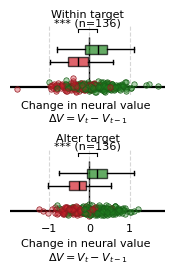

In [9]:
# Create the figure
fig, axs = plt.subplots(2, 1, figsize=(2, 2.5), sharex=True, gridspec_kw={'height_ratios': [1, 1], 'hspace': .8})

# Create the plots
palette = {'0': 'tab:red', '1': 'tab:green'}

# Within target plot
plot_RL_vs_forage_single_sess_horizontal(axs[0],
                   results_df_temp.loc[results_df_temp['type'] == 'within'], 
                   'feedback', 'dV_neural', paper_format=True)
axs[0].set_title('Within target', fontsize=8)

# Alter target plot
plot_RL_vs_forage_single_sess_horizontal(axs[1], 
                   results_df_temp.loc[results_df_temp['type'] == 'alter'],
                   'feedback', 'dV_neural', paper_format=True)
axs[1].set_title('Alter target', fontsize=8)

# save svg
fig.savefig(os.path.join(base_path, 'single_session_ka_21322_mcc.svg'), 
            bbox_inches='tight', dpi=300, transparent=True)

In [10]:
# Export source data (Figure 5c)
from popy.source_data import export_source_data
from matplotlib.cbook import boxplot_stats  # the statistics drawn by ax.boxplot

conditions = {'within': 'Within target', 'alter': 'Across target'}
outcomes = {0: 'Unrewarded', 1: 'Rewarded'}

trial_tables, box_rows = [], []
for type_, condition in conditions.items():
    data_type = results_df_temp.loc[results_df_temp['type'] == type_]  # data plotted above
    trial_tables.append(pd.DataFrame({
        'Monkey': data_type['monkey'].str.upper(),
        'Session': data_type['session'],
        'Area': data_type['subregion'],
        'Condition': condition,
        'Trial t': data_type['trial_id'],
        'Outcome of trial t': data_type['feedback'].map(outcomes),
        'Delta V_neural = V(t+1) - V(t) (arb. units)': data_type['dV_neural'],
    }))
    for feedback, outcome in outcomes.items():
        values = data_type.loc[data_type['feedback'] == feedback, 'dV_neural'].values
        box = boxplot_stats(values)[0]
        box_rows.append({
            'Condition': condition, 'Outcome of trial t': outcome, 'n trials': len(values),
            'Median (arb. units)': box['med'], 'Q1 (arb. units)': box['q1'], 'Q3 (arb. units)': box['q3'],
            'Lower whisker (arb. units)': box['whislo'], 'Upper whisker (arb. units)': box['whishi'],
            'Mean (end of the significance bracket, arb. units)': values.mean(),
        })

export_source_data(
    'Figure 5c',
    {'Trial-by-trial change in neural value (dots)': pd.concat(trial_tables, ignore_index=True),
     'Box plots': pd.DataFrame(box_rows)},
    'Example MCC session (monkey KA, session 210322): change in neural value (Delta V_neural, projection on the decision '
    'vector of the outcome decoder, arbitrary units) from trial t to trial t+1 (same chosen target), by outcome of trial t; '
    'within target (top): subspace of the chosen target; across target (bottom): mean over the subspaces of the two other '
    'targets. One dot per trial (the vertical jitter of the dots is random and not exported). Box plots: median, quartiles '
    '(Q1, Q3) and whiskers (most extreme values within 1.5 x IQR of the quartiles); the significance bracket connects the means.',
)

Figure 5c: source data saved (748 rows, 4 rows)


---
# Value-coding hypothesis in the within-target condition

The same test as in Fig. 4 (delta-rule consistent update), now in the within-target condition.

In [11]:
# summarize value coding hypothesis per session
session_summary = make_session_summary(res)
session_summary

,monkey,session,subregion,hypothesis
0,ka,010720,MCC,Delta rule (strict)
1,ka,010720,vLPFC,Delta rule (loose)
2,ka,010822,MCC,Delta rule (loose)
3,ka,010822,dLPFC,Other
4,ka,010922,MCC,Other
...,...,...,...,...
197,po,300322,vLPFC,Other
198,po,300421,MCC,Delta rule (loose)
199,po,300421,dLPFC,Feedback
200,po,310822,MCC,Other


In [12]:
# get mean modulation per session
results_df_mean = get_session_mean_value(res, session_summary)
results_df_mean

,monkey,session,subregion,type,feedback,dV_neural,V_neural,V_neural_p1,dV_signif,value_coding
0,ka,010720,MCC,alter,1,0.111676,0.044528,0.156204,True,Delta rule (strict)
1,ka,010720,MCC,alter,0,-0.121358,0.044960,-0.076399,True,Delta rule (strict)
2,ka,010720,MCC,within,1,0.121374,0.079801,0.201175,True,Delta rule (strict)
3,ka,010720,MCC,within,0,-0.146974,0.010909,-0.136065,True,Delta rule (strict)
4,ka,010720,vLPFC,alter,1,0.014721,-0.020156,-0.005435,False,Delta rule (loose)
...,...,...,...,...,...,...,...,...,...,...
803,po,310822,MCC,within,1,-0.016811,0.066171,0.049360,False,Other
804,po,310822,dLPFC,alter,0,-0.002223,-0.025594,-0.027817,False,Other
805,po,310822,dLPFC,alter,1,0.009231,-0.018640,-0.009408,False,Other
806,po,310822,dLPFC,within,0,0.035507,-0.024893,0.010613,False,Other


In [13]:
# use only delta consistent sessions
is_delta = results_df_mean['value_coding'].isin(['Delta rule (loose)', 'Delta rule (strict)'])
results_df_mean_delta = results_df_mean[is_delta]

# print num session per area that is is_delta
for subregion in results_df_mean['subregion'].unique():
    for monkey in results_df_mean['monkey'].unique():
        data_total = results_df_mean.loc[(results_df_mean['subregion'] == subregion) & (results_df_mean['monkey'] == monkey)]
        data_delta = results_df_mean_delta.loc[(results_df_mean_delta['subregion'] == subregion) & (results_df_mean_delta['monkey'] == monkey)]
        n_sessions_total = len(np.unique(data_total.session))
        n_sessions_delta = len(np.unique(data_delta.session))
        print(monkey, subregion, f"{n_sessions_delta}/{n_sessions_total} sessions are delta consistent")

ka MCC 37/58 sessions are delta consistent
po MCC 26/45 sessions are delta consistent
ka vLPFC 4/12 sessions are delta consistent
po vLPFC 3/6 sessions are delta consistent
ka dLPFC 14/46 sessions are delta consistent
po dLPFC 8/35 sessions are delta consistent


---
# Fig. 5d, Within- vs. across-target change of the neural value


===== Fig. 5d (top marginal, within-target) | monkey: KA, PO | subregion: MCC =====
  Group test: two-sided Wilcoxon signed-rank test, paired by session, dV_neural of 1 - 0 (feedback)
  n = 63 sessions (63 non-zero differences); median difference = 0.191 (IQR 0.121 to 0.259)
  95% CI of the median difference (bootstrap over sessions, 10000 resamples): [0.158, 0.218]
  W = 0.0, p = 5.168e-12, p (Bonferroni x3) = 1.551e-11
  Effect size: matched-pairs rank-biserial r = 1.000

===== Fig. 5d (right marginal, across-target) | monkey: KA, PO | subregion: MCC =====
  Group test: two-sided Wilcoxon signed-rank test, paired by session, dV_neural of 1 - 0 (feedback)
  n = 63 sessions (63 non-zero differences); median difference = 0.188 (IQR 0.118 to 0.251)
  95% CI of the median difference (bootstrap over sessions, 10000 resamples): [0.154, 0.216]
  W = 4.0, p = 6.265e-12, p (Bonferroni x3) = 1.880e-11
  Effect size: matched-pairs rank-biserial r = 0.996

===== Fig. 5d (top marginal, within-tar

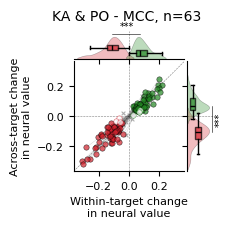

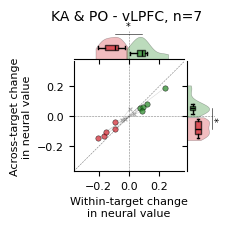

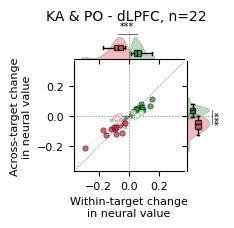

In [14]:
plot_per_monkey = False

# Keep extracted scatter dataframes for inspection
scatter_tables = {}

# Use one global limit so every subplot has identical x/y scales.
global_abs_lim = np.nanmax(np.abs(results_df_mean_delta['dV_neural'].values)) * 1.15

# Use 0.1-resolution ticks, constrained to fall within the plot limits.
tick_step = 0.2
tick_min = np.ceil((-global_abs_lim) / tick_step) * tick_step
tick_max = np.floor(global_abs_lim / tick_step) * tick_step
shared_ticks = np.round(np.arange(tick_min, tick_max + tick_step / 2, tick_step), 2)

for subregion in results_df_mean_delta['subregion'].unique():
    data = results_df_mean_delta.loc[(results_df_mean_delta['subregion'] == subregion)]

    # 1) Extract readable pandas DataFrame
    prepared = prepare_2d_scatter_data(data)
    scatter_df = prepared['scatter_df'].copy()
    #scatter_df = scatter_df.sort_values(['session', 'feedback']).reset_index(drop=True)
    scatter_tables[subregion] = scatter_df

    # 2) Plot from preprocessed data
    fig, ax_main, ax_top, ax_right = plot_2d_scatter_with_marginals(
        scatter_df=scatter_df,
        x_data=prepared['x_data'],
        y_data=prepared['y_data'],
        palette=COLORS,
        paper_format=True,
    )
    ax_main.set_xlim(-global_abs_lim, global_abs_lim)
    ax_main.set_ylim(-global_abs_lim, global_abs_lim)
    ax_main.set_xticks(shared_ticks)
    ax_main.set_yticks(shared_ticks)
    ax_top.set_xlim(ax_main.get_xlim())
    ax_right.set_ylim(ax_main.get_ylim())
    # Ensure identity line spans the full shared limits.
    ax_main.plot(
        [-global_abs_lim, global_abs_lim],
        [-global_abs_lim, global_abs_lim],
        'k--',
        alpha=0.5,
        zorder=0,
        linewidth=0.4,
    )
    fig.suptitle(f'KA & PO - {subregion}, n={len(np.unique(data.session))}', fontsize=10)

    fig.savefig(
        os.path.join(base_path, f'scatter_single_session_KAPO_{subregion}.svg'),
        bbox_inches='tight',
        dpi=300,
        transparent=True,
    )

    if plot_per_monkey:
        for monkey in results_df_mean_delta['monkey'].unique():
            data = results_df_mean_delta.loc[
                (results_df_mean_delta['subregion'] == subregion)
                & (results_df_mean_delta['monkey'] == monkey)
            ]

            prepared = prepare_2d_scatter_data(data)
            scatter_df = prepared['scatter_df'].copy()#.sort_values(['session', 'feedback']).reset_index(drop=True)

            fig, ax_main, ax_top, ax_right = plot_2d_scatter_with_marginals(
                scatter_df=scatter_df,
                x_data=prepared['x_data'],
                y_data=prepared['y_data'],
                palette=COLORS,
                paper_format=True,
            )
            ax_main.set_xlim(-global_abs_lim, global_abs_lim)
            ax_main.set_ylim(-global_abs_lim, global_abs_lim)
            ax_main.set_xticks(shared_ticks)
            ax_main.set_yticks(shared_ticks)
            ax_top.set_xlim(ax_main.get_xlim())
            ax_right.set_ylim(ax_main.get_ylim())
            # Ensure identity line spans the full shared limits.
            ax_main.plot(
                [-global_abs_lim, global_abs_lim],
                [-global_abs_lim, global_abs_lim],
                'k--',
                alpha=0.5,
                zorder=0,
                linewidth=0.4,
            )
            fig.suptitle(f'{monkey.capitalize()} - {subregion}, n={len(np.unique(data.session))}', fontsize=10)

            fig.savefig(
                os.path.join(base_path, f'scatter_single_session_{monkey}_{subregion}.svg'),
                bbox_inches='tight',
                dpi=300,
                transparent=True,
            )

In [15]:
# Export source data (Figure 5d)
from popy.source_data import export_source_data

outcomes = {'0': 'unrewarded', '1': 'rewarded'}
session_monkey = results_df_mean_delta[['subregion', 'session', 'monkey']].drop_duplicates()
fig5d_tables = {}
for subregion in ['MCC', 'dLPFC', 'vLPFC']:
    rows = []
    for session, points in scatter_tables[subregion].groupby('session', sort=False):  # points plotted above
        monkey = session_monkey.loc[(session_monkey['subregion'] == subregion) & (session_monkey['session'] == session), 'monkey']
        assert len(monkey) == 1 and len(points) == 2
        row = {'Monkey': monkey.iloc[0].upper(), 'Session': session, 'Area': subregion,
               'Within-target modulation significant (circle if True, cross if False)': points['signif_same'].iloc[0],
               'Across-target modulation significant (filled circle if True)': points['signif_alter'].iloc[0]}
        for feedback, outcome in outcomes.items():
            point = points[points['feedback'] == feedback]
            row[f'Within-target Delta V_neural, {outcome} (x, arb. units)'] = point['x'].iloc[0]
            row[f'Across-target Delta V_neural, {outcome} (y, arb. units)'] = point['y'].iloc[0]
        rows.append(row)
    fig5d_tables[f'{subregion}, n = {len(rows)} sessions'] = pd.DataFrame(rows)

export_source_data(
    'Figure 5d',
    fig5d_tables,
    'Session averages of the trial-by-trial change in neural value (Delta V_neural, arbitrary units) within target (x) and '
    'across target (y), after unrewarded and rewarded trials (one pair of points per session, both monkeys), in the sessions '
    'with within-target delta-rule-consistent value coding (' + '; '.join(fig5d_tables) + '). Marker: within-target feedback '
    'modulation of Delta V_neural significant (circle) or not (cross); circle filled if the across-target modulation is '
    'significant (two-sided Mann-Whitney U test over the trials of the session, rewarded vs. unrewarded, p < 0.05). Marginals: '
    'kernel density estimates (scaled to the same height) and box plots of the same session values.',
)

Figure 5d: source data saved (63 rows, 22 rows, 7 rows)


---
# Fig. 5e, Fraction of sessions per hypothesis

Subregion: vLPFC, Hypothesis: none, Proportion: 28.6% (2/7 sessions)
Subregion: vLPFC, Hypothesis: Foraging, Proportion: 71.4% (5/7 sessions)
Subregion: vLPFC, Hypothesis: Inferential RL, Proportion: 0.0% (0/7 sessions)
Subregion: vLPFC, Hypothesis: Standard RL, Proportion: 0.0% (0/7 sessions)
Subregion: dLPFC, Hypothesis: none, Proportion: 31.8% (7/22 sessions)
Subregion: dLPFC, Hypothesis: Foraging, Proportion: 50.0% (11/22 sessions)
Subregion: dLPFC, Hypothesis: Inferential RL, Proportion: 0.0% (0/22 sessions)
Subregion: dLPFC, Hypothesis: Standard RL, Proportion: 18.2% (4/22 sessions)
Subregion: MCC, Hypothesis: none, Proportion: 11.1% (7/63 sessions)
Subregion: MCC, Hypothesis: Foraging, Proportion: 84.1% (53/63 sessions)
Subregion: MCC, Hypothesis: Inferential RL, Proportion: 0.0% (0/63 sessions)
Subregion: MCC, Hypothesis: Standard RL, Proportion: 4.8% (3/63 sessions)
Subregion: vLPFC, Hypothesis: none, Proportion: 25.0% (1/4 sessions)
Subregion: vLPFC, Hypothesis: Foraging, Pro

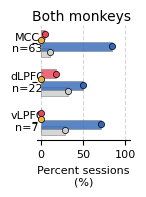

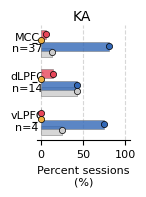

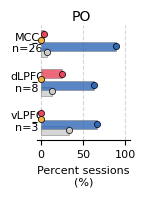

In [16]:
# Extract hypothesis info

stats_df = extract_hypothesis(results_df_mean_delta, detailed=False)

stats_df

# print stats

fig_bar_both, _, _, _ = print_stats_both(stats_df)
fig_bar_ka, _, _, _ = print_stats_both(stats_df.loc[stats_df['monkey'] == 'ka'])
fig_bar_po, _, _, _ = print_stats_both(stats_df.loc[stats_df['monkey'] == 'po'])

fig_bar_both.suptitle('Both monkeys', fontsize=10)
fig_bar_ka.suptitle('KA', fontsize=10)
fig_bar_po.suptitle('PO', fontsize=10)

# save figure
fig_bar_both.savefig(os.path.join(base_path, 'RL_forage_bars_both.svg'), format='svg', bbox_inches='tight', dpi=300, transparent=True)
fig_bar_ka.savefig(os.path.join(base_path, 'RL_forage_bars_ka.svg'), format='svg', bbox_inches='tight', dpi=300, transparent=True)
fig_bar_po.savefig(os.path.join(base_path, 'RL_forage_bars_po.svg'), format='svg', bbox_inches='tight', dpi=300, transparent=True)

In [17]:
# Export source data (Figure 5e)
from popy.source_data import export_source_data

counts = stats_df.groupby(['subregion', 'hypothesis'])['count'].sum()  # both monkeys, as in fig_bar_both
rows = []
for subregion in ['MCC', 'dLPFC', 'vLPFC']:
    n_total = int(counts.loc[subregion].sum())
    for hypothesis in ['Standard RL', 'Inferential RL', 'Foraging', 'none']:
        n = int(counts.get((subregion, hypothesis), 0))
        rows.append({'Area': subregion, 'Hypothesis': 'None of the hypotheses' if hypothesis == 'none' else hypothesis,
                     'n sessions supporting the hypothesis': n, 'n sessions (total)': n_total,
                     'Percent sessions (%)': 100 * n / n_total})

export_source_data(
    'Figure 5e',
    pd.DataFrame(rows),
    'Percentage of sessions (both monkeys) supporting each hypothesis, relative to the sessions with within-target '
    'delta-rule-consistent value coding (n sessions (total), as in Fig. 5d). Standard RL: significant positive within-target '
    'and non-significant across-target feedback modulation of Delta V_neural; Inferential RL: significant positive within-target '
    'and significant negative across-target modulation; Foraging: significant positive modulation in both; None: all other '
    'sessions ("None" in the legend; two-sided Mann-Whitney U test over trials, rewarded vs. unrewarded, p < 0.05).',
)

Figure 5e: source data saved (12 rows)
